In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("data/penguins.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("First 5 Rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

First 5 Rows:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007



Dataset Shape:
(344, 8)

Column Names:
Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB


In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nSpecies Distribution:")
print(df["species"].value_counts())

Missing Values:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Duplicate Rows:
0

Species Distribution:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB


In [7]:
print("Before Cleaning:", df.shape)

df = df.dropna()

print("After Cleaning:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Before Cleaning: (344, 8)
After Cleaning: (333, 8)

Missing Values After Cleaning:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64


In [8]:
print("Duplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape After Removing Duplicates:", df.shape)

Duplicate Records: 0
Shape After Removing Duplicates: (333, 8)


In [9]:
X = df.drop(columns=["species"])

y = df["species"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
      island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  \
0  Torgersen            39.1           18.7              181.0       3750.0   
1  Torgersen            39.5           17.4              186.0       3800.0   
2  Torgersen            40.3           18.0              195.0       3250.0   
4  Torgersen            36.7           19.3              193.0       3450.0   
5  Torgersen            39.3           20.6              190.0       3650.0   

      sex  year  
0    male  2007  
1  female  2007  
2  female  2007  
4  female  2007  
5    male  2007  

Target:
0    Adelie
1    Adelie
2    Adelie
4    Adelie
5    Adelie
Name: species, dtype: str


In [10]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoded Features:")
display(X.head())

print("\nFeature Columns:")
print(X.columns.tolist())

Encoded Features:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year,island_Dream,island_Torgersen,sex_male
0,39.1,18.7,181.0,3750.0,2007,0,1,1
1,39.5,17.4,186.0,3800.0,2007,0,1,0
2,40.3,18.0,195.0,3250.0,2007,0,1,0
4,36.7,19.3,193.0,3450.0,2007,0,1,0
5,39.3,20.6,190.0,3650.0,2007,0,1,1



Feature Columns:
['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'year', 'island_Dream', 'island_Torgersen', 'sex_male']


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (266, 8)
Testing Data: (67, 8)


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

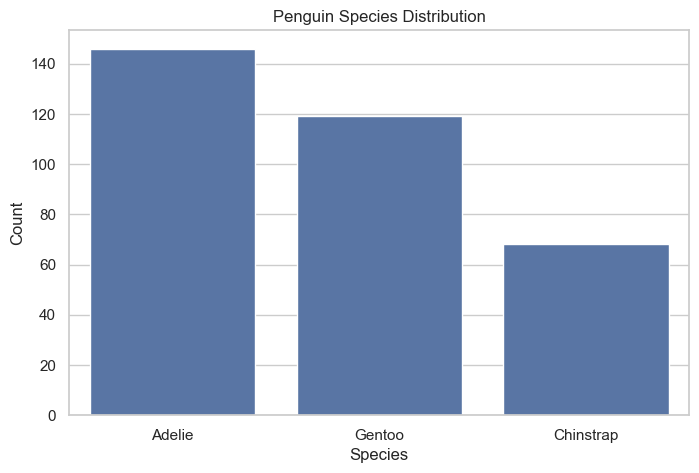

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Penguin Species Distribution")
plt.xlabel("Species")
plt.ylabel("Count")

plt.savefig("images/species_distribution.png")
plt.show()

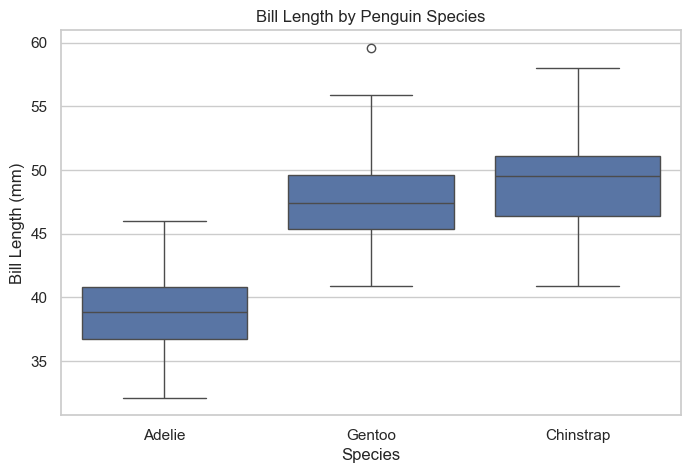

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="species", y="bill_length_mm")

plt.title("Bill Length by Penguin Species")
plt.xlabel("Species")
plt.ylabel("Bill Length (mm)")

plt.savefig("images/bill_length.png")
plt.show()

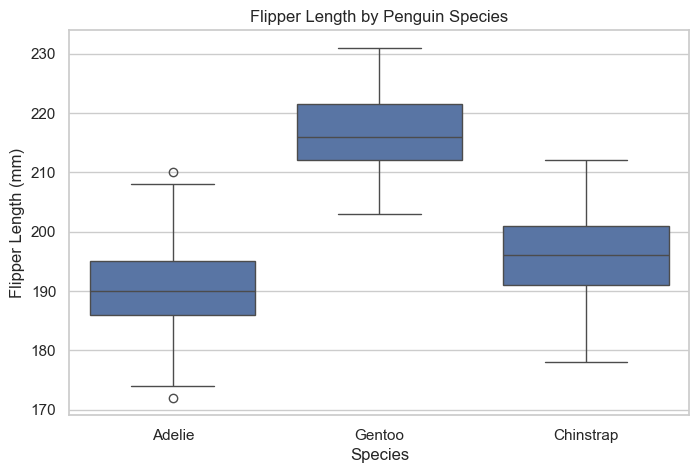

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="species", y="flipper_length_mm")

plt.title("Flipper Length by Penguin Species")
plt.xlabel("Species")
plt.ylabel("Flipper Length (mm)")

plt.savefig("images/flipper_length.png")
plt.show()

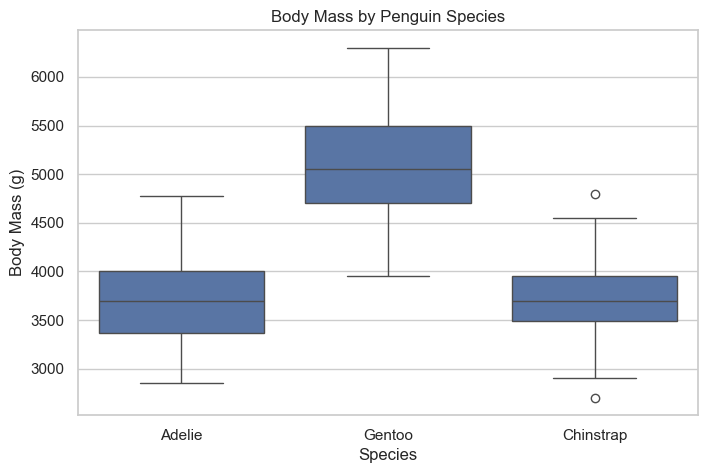

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="species", y="body_mass_g")

plt.title("Body Mass by Penguin Species")
plt.xlabel("Species")
plt.ylabel("Body Mass (g)")

plt.savefig("images/body_mass.png")
plt.show()

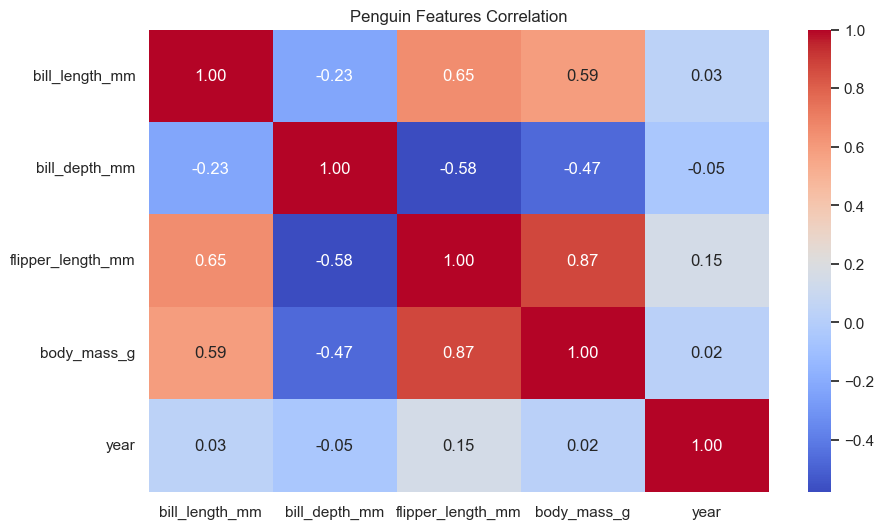

In [18]:
plt.figure(figsize=(10, 6))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Penguin Features Correlation")

plt.savefig("images/correlation_heatmap.png")
plt.show()

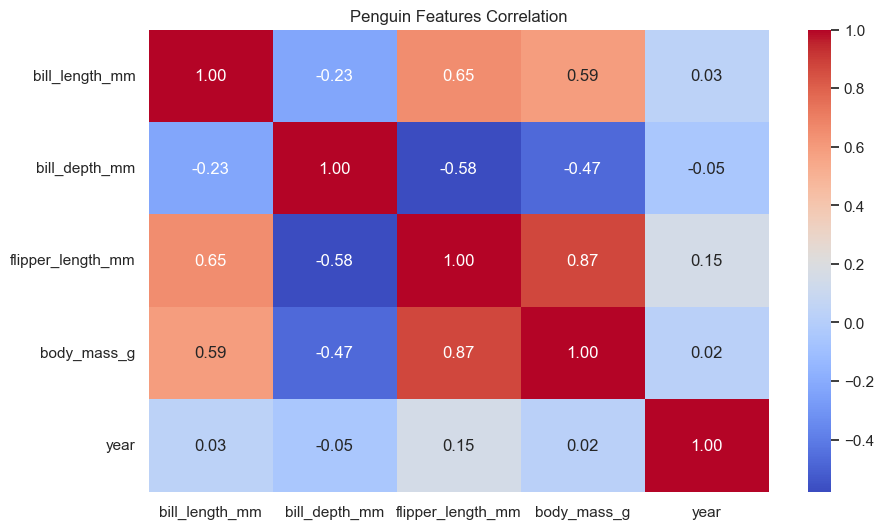

In [19]:
plt.figure(figsize=(10, 6))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Penguin Features Correlation")

plt.savefig("images/correlation_heatmap.png")
plt.show()

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

In [21]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

Decision Tree Accuracy: 92.53731343283582 %


In [22]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

knn_predictions = knn_model.predict(X_test)

knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Accuracy:", knn_accuracy * 100, "%")

KNN Accuracy: 73.13432835820896 %


In [23]:
results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Accuracy": [
        dt_accuracy * 100,
        knn_accuracy * 100
    ]
})

display(results)

,Model,Accuracy
0,Decision Tree,92.537313
1,KNN,73.134328


In [24]:
print("Decision Tree Report")

print(
    classification_report(
        y_test,
        dt_predictions
    )
)

Decision Tree Report
              precision    recall  f1-score   support

      Adelie       0.93      0.90      0.91        29
   Chinstrap       0.82      1.00      0.90        14
      Gentoo       1.00      0.92      0.96        24

    accuracy                           0.93        67
   macro avg       0.92      0.94      0.92        67
weighted avg       0.93      0.93      0.93        67



In [25]:
print("KNN Classification Report")

print(
    classification_report(
        y_test,
        knn_predictions
    )
)

KNN Classification Report
              precision    recall  f1-score   support

      Adelie       0.66      0.86      0.75        29
   Chinstrap       0.75      0.21      0.33        14
      Gentoo       0.84      0.88      0.86        24

    accuracy                           0.73        67
   macro avg       0.75      0.65      0.65        67
weighted avg       0.74      0.73      0.70        67



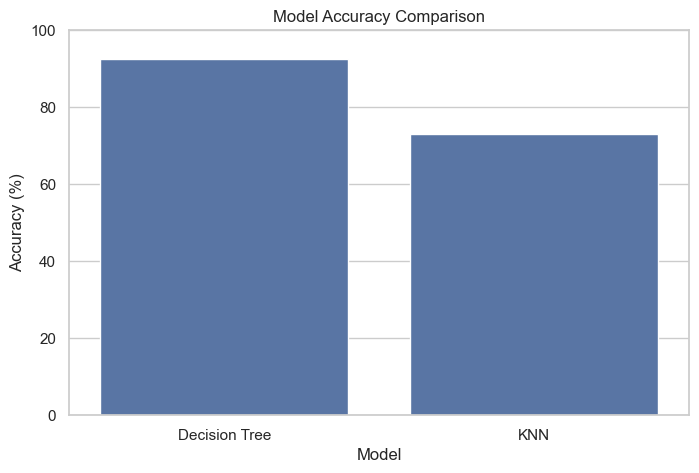

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.savefig("images/model_accuracy.png")
plt.show()

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

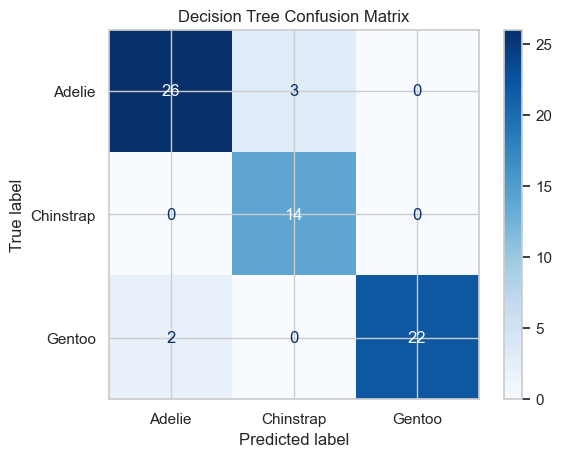

In [30]:
cm_dt = confusion_matrix(y_test, dt_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=dt_model.classes_
)

disp.plot(cmap="Blues")

plt.title("Decision Tree Confusion Matrix")
plt.savefig("images/decision_tree_confusion_matrix.png")
plt.show()

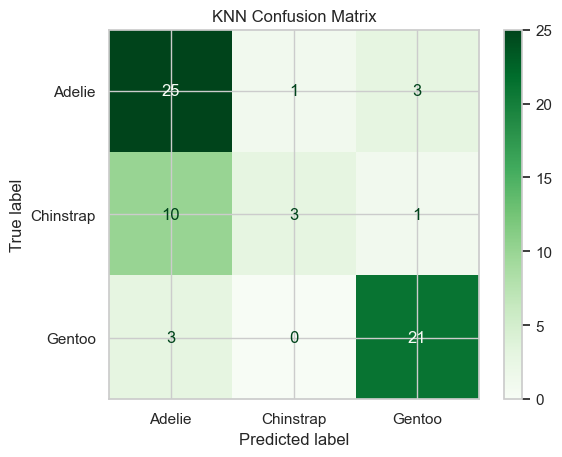

In [31]:
cm_knn = confusion_matrix(y_test, knn_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=knn_model.classes_
)

disp.plot(cmap="Greens")

plt.title("KNN Confusion Matrix")
plt.savefig("images/knn_confusion_matrix.png")
plt.show()

In [32]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [33]:
knn_scaled_model = KNeighborsClassifier(n_neighbors=5)

knn_scaled_model.fit(X_train_scaled, y_train)

scaled_predictions = knn_scaled_model.predict(X_test_scaled)

scaled_accuracy = accuracy_score(y_test, scaled_predictions)

print("Scaled KNN Accuracy:", scaled_accuracy * 100, "%")

Scaled KNN Accuracy: 97.01492537313433 %


In [34]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "KNN",
        "Scaled KNN"
    ],
    "Accuracy": [
        dt_accuracy * 100,
        knn_accuracy * 100,
        scaled_accuracy * 100
    ]
})

display(results.sort_values(by="Accuracy", ascending=False))

,Model,Accuracy
2,Scaled KNN,97.014925
0,Decision Tree,92.537313
1,KNN,73.134328


In [35]:
best_model_name = results.loc[
    results["Accuracy"].idxmax(), "Model"
]

print("Best Model:", best_model_name)

Best Model: Scaled KNN


In [36]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
2,flipper_length_mm,0.543802
0,bill_length_mm,0.365212
1,bill_depth_mm,0.059218
5,island_Dream,0.031769
3,body_mass_g,0.000000
4,year,0.000000
6,island_Torgersen,0.000000
7,sex_male,0.000000


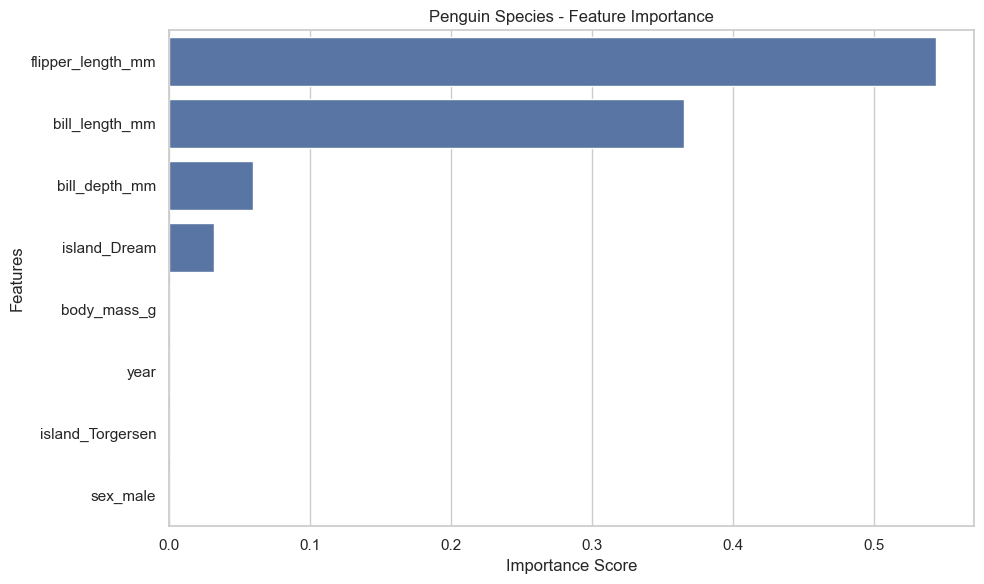

In [38]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Penguin Species - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.savefig("images/feature_importance.png")
plt.show()

In [39]:
import joblib
import os

In [40]:
models = {
    "Decision Tree": dt_model,
    "KNN": knn_model,
    "Scaled KNN": knn_scaled_model
}

best_model = models[best_model_name]

print("Selected Model:", best_model_name)

Selected Model: Scaled KNN


In [41]:
os.makedirs("../models", exist_ok=True)

joblib.dump(best_model, "../models/penguin_model.pkl")

if best_model_name == "Scaled KNN":
    joblib.dump(scaler, "models/scaler.pkl")

print("Model saved successfully!")

Model saved successfully!


In [47]:
new_penguin = pd.DataFrame([{
    "bill_length_mm": 45.0,
    "bill_depth_mm": 15.0,
    "flipper_length_mm": 215.0,
    "body_mass_g": 5000,
    "island_Dream": 0,
    "island_Torgersen": 0,
    "sex_MALE": 2
}])

new_penguin = new_penguin.reindex(
    columns=X.columns,
    fill_value=0
)

if best_model_name == "Scaled KNN":
    new_penguin_scaled = scaler.transform(new_penguin)
    prediction = best_model.predict(new_penguin_scaled)
else:
    prediction = best_model.predict(new_penguin)

print("Predicted Penguin Species:", prediction[0])

Predicted Penguin Species: Gentoo
